In [1]:
import pandas as pd

Dateipfad angeben

In [ ]:
file_path = "https://raw.github.com/jan-source/ppa_erp_student/main/sessions/2_session/"

#### Nutze ";" als Trennzeichen: 
data_a = pd.read_csv('churn_part_a.csv', delimiter = ';')

In [ ]:
data_a = pd.read_csv(f'{file_path}churn_part_a.csv')

In [4]:
data_a.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0


In [ ]:
data_b = pd.read_csv(f'{file_path}churn_part_b.csv')

In [6]:
data_b.head()

,CustomerId,Geography,Gender,Age
0,15634602,France,Female,42.0
1,15647311,Spain,Female,NaN
2,15619304,France,Female,42.0
3,15701354,France,Female,39.0
4,15737888,Spain,Female,43.0


### Combine Datasets
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.merge.html

In [7]:
data = pd.merge(data_a, data_b, how='inner', on='CustomerId')

In [8]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0
1,2,15647311,Hill,608,1,83807.86,1,0,1,112542.58,0,Spain,Female,NaN
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0


In [9]:
data.shape

(10000, 14)

In [10]:
data_a.shape

(10000, 11)

In [11]:
data_b.shape

(10000, 4)

### %-Anteil der Kunden die uns verlassen haben

In [12]:
data["Exited"].sum()/data.shape[0]

np.float64(0.2037)

### Ermittle Anzahl vollständiger Datensätze

In [13]:
data.dropna(axis=0).shape

(9996, 14)

### "Entferne"  Zeilen, in denen entweder Gender oder Age oder Beides NaN ist

In [14]:
data.dropna(axis=0, subset=['Gender', 'Age']).shape

(9997, 14)

In [15]:
data.shape

(10000, 14)

In [16]:
### Erstelle Datensatz in dem die Zeilen mit NaNs entfernt wurden

In [17]:
data_cleaned = data.dropna(axis=0)

In [18]:
data_cleaned.shape

(9996, 14)

### Visuelle Analyse

In [19]:
import matplotlib.pyplot as plt

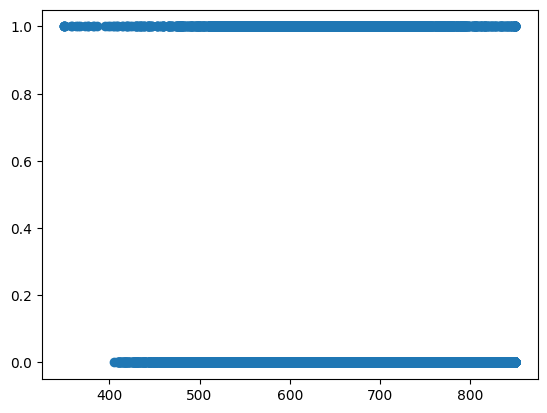

In [20]:
plt.scatter(data_cleaned['CreditScore'], data_cleaned['Exited'])

In [21]:
data_cleaned.groupby('Exited')['CreditScore'].mean()

Exited
0    651.844598
1    645.347741
Name: CreditScore, dtype: float64

In [22]:
data_cleaned.groupby('Exited')['Age'].mean()

Exited
0    37.410427
1    44.831532
Name: Age, dtype: float64

In [23]:
data_cleaned.groupby('Exited')['Age'].min()

Exited
0    18.0
1    18.0
Name: Age, dtype: float64

### 1. Vorhersagemodel: Logistische Regression

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

### Selektiere Features (Variablen die für die Vorhersage genutzt werden)

In [25]:
x = data_cleaned[['Age', 'CreditScore', 'Balance']]

In [26]:
random_variable = 1234

In [27]:
log_reg_simple = LogisticRegression(random_state=random_variable)

In [28]:
log_reg_simple.fit(x, data_cleaned['Exited'])

LogisticRegression(random_state=1234)

In [29]:
log_reg_simple.coef_

array([[ 6.33155132e-02, -7.71750832e-04,  5.02711176e-06]])

### Zeige Koeffizienten formatiert an

In [30]:
import numpy as np

In [31]:
coefficients_formated =  pd.concat(
    [
     pd.Series(['Age', 'CreditScore', 'Balance']),
     pd.DataFrame(np.transpose(log_reg_simple.coef_))
    ],
     axis=1
 )

In [32]:
coefficients_formated

,0,0
0,Age,0.063316
1,CreditScore,-0.000772
2,Balance,0.000005


### Berechne Wahrscheinlichkeit dass uns ein Kunden verlässt (Exited = 1)

In [33]:
log_reg_simple.predict_proba(x)

array([[0.84242597, 0.15757403],
       [0.68642596, 0.31357404],
       [0.87303642, 0.12696358],
       ...,
       [0.89338001, 0.10661999],
       [0.80487652, 0.19512348],
       [0.8851447 , 0.1148553 ]], shape=(9996, 2))

jeder Kunde erhählt eine Wahrscheinlichkeit dass er bei uns bleibt (Exited=0) und eine dass er uns verlässt (Exited=1)

### Vorhersage ob Kunden uns verlässt (1) oder bei uns bleibt (0), jede Zahl repräsentiert einen Kunden


In [34]:
log_reg_simple.predict(x)

array([0, 0, 0, ..., 0, 0, 0], shape=(9996,))

### Berechnung Confusion Matrix

In [35]:
predictions = log_reg_simple.predict(x)

confusion_matrix(beboachtete Werte, vorhergesagte Werte, Sortierung)

In [36]:
cnf_matrix = metrics.confusion_matrix(
                    data_cleaned['Exited'], 
                    predictions, 
                    labels = [True, False]
                )

In [37]:
cnf_matrix

array([[ 125, 1911],
       [ 286, 7674]])

In [38]:
accuracy = (113 + 7779)/(113 + 1923 + 181 + 7779)

In [39]:
accuracy

0.789515806322529

In [40]:
precision = 113/(113 + 181)

In [41]:
precision

0.3843537414965986

### Model with more variables

In [42]:
data_cleaned.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0


In [43]:
x = data_cleaned[['Age', 'CreditScore', 'Balance', 'EstimatedSalary']]

In [44]:
log_reg_simple = LogisticRegression(random_state=random_variable)

In [45]:
log_reg_simple.fit(x, data_cleaned['Exited'])

LogisticRegression(random_state=1234)

In [46]:
log_reg_simple.coef_

array([[ 6.33683938e-02, -7.70494375e-04,  5.02090353e-06,
         6.37903864e-07]])

In [47]:
predictions = log_reg_simple.predict(x)

In [48]:
cnf_matrix = metrics.confusion_matrix(
                    data_cleaned['Exited'], 
                    predictions, 
                    labels = [True, False]
                )

In [49]:
cnf_matrix

array([[ 127, 1909],
       [ 288, 7672]])

In [50]:
112/(112+ 176)

0.3888888888888889

### Berechnung Accuracy mit implementierter Lösung

In [51]:
metrics.accuracy_score(data_cleaned['Exited'], 
                    predictions)

0.7802120848339336

### Berechnung Precision mit implementierter Lösung

In [52]:
metrics.precision_score(data_cleaned['Exited'], 
                    predictions)

0.3060240963855422

### Erzeugen von Spalte die den Wert True bei Frauen animmt und False bei Männern

In [53]:
data_cleaned['Gender_Boolean'] = data['Gender'] == 'Female'

/var/folders/2t/qqms9sv564dfb0p55s5xfyy00000gn/T/ipykernel_16040/2184254904.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned['Gender_Boolean'] = data['Gender'] == 'Female'


In [54]:
data_cleaned.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age,Gender_Boolean
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0,True
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0,True
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0,True
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0,True
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0,False


### Umwandeln in Zahl

In [55]:
data_cleaned['Gender_numeric'] = data_cleaned['Gender_Boolean'].astype(int)

/var/folders/2t/qqms9sv564dfb0p55s5xfyy00000gn/T/ipykernel_16040/1977041434.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned['Gender_numeric'] = data_cleaned['Gender_Boolean'].astype(int)


In [56]:
data_cleaned.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age,Gender_Boolean,Gender_numeric
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0,True,1
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0,True,1
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0,True,1
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0,True,1
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0,False,0


In [57]:
data_cleaned['Geography'].unique()

array(['France', 'Spain', 'Germany'], dtype=object)

### Generierung Dummy Encoding für die Spalte Geography

In [58]:
geography_dummies = pd.get_dummies(data_cleaned['Geography'], prefix="g")

In [59]:
geography_dummies

,g_France,g_Germany,g_Spain
0,True,False,False
2,True,False,False
3,True,False,False
4,False,False,True
5,False,False,True
...,...,...,...
9995,True,False,False
9996,True,False,False
9997,True,False,False
9998,False,True,False


### Mergen von data_cleaned und geography_dummies (Spalten zu data_cleaned hinzfügen)

In [60]:
data_full = pd.concat([data_cleaned, geography_dummies], axis=1)

In [61]:
data_full

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age,Gender_Boolean,Gender_numeric,g_France,g_Germany,g_Spain
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0,True,1,True,False,False
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0,True,1,True,False,False
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0,True,1,True,False,False
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0,True,1,False,False,True
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0,False,0,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,5,0.00,2,1,0,96270.64,0,France,Male,39.0,False,0,True,False,False
9996,9997,15569892,Johnstone,516,10,57369.61,1,1,1,101699.77,0,France,Male,35.0,False,0,True,False,False
9997,9998,15584532,Liu,709,7,0.00,1,0,1,42085.58,1,France,Female,36.0,True,1,True,False,False
9998,9999,15682355,Sabbatini,772,3,75075.31,2,1,0,92888.52,1,Germany,Male,42.0,False,0,False,True,False


### Neues Modell mit Herkunftsland und Geschlecht

In [62]:
features = ['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Gender_numeric',
                 'g_Spain', 'g_Germany']

In [63]:
x_full = data_full[['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Gender_numeric',
                 'g_Spain', 'g_Germany']]

In [64]:
log_reg_simple = LogisticRegression(random_state=random_variable)

In [65]:
log_reg_simple.fit(x_full, data_full['Exited'])

/Users/janmammen/Library/CloudStorage/OneDrive-Personal/14 OHM/00 lehre/03_ERP_Verantaltung/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(random_state=1234)

In [66]:
predictions_full = log_reg_simple.predict(x_full)

In [67]:
cnf_matrix = metrics.confusion_matrix(
                    data_full['Exited'], 
                    predictions_full, 
                    labels = [True, False]
                )

In [68]:
cnf_matrix

array([[ 227, 1809],
       [ 244, 7716]])

In [69]:
metrics.accuracy_score(data_full['Exited'], 
                    predictions_full)

0.7946178471388555

In [70]:
metrics.precision_score(data_full['Exited'], 
                    predictions_full)

0.4819532908704883

In [71]:
coefficients_formated =  pd.concat(
    [
     pd.Series(['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Gender_numeric',
                 'g_Spain', 'g_Germany']),
     pd.DataFrame(np.transpose(log_reg_simple.coef_))
    ],
     axis=1
 )

In [72]:
coefficients_formated

,0,0
0,Age,0.044184
1,CreditScore,-0.004939
2,Balance,0.000002
3,EstimatedSalary,-0.000001
4,Gender_numeric,0.512735
5,g_Spain,-0.286643
6,g_Germany,0.639685


### Decision Tree

In [73]:
from sklearn import tree

Entscheidungsbaum mit 3 Leveln (Depth)

In [74]:
clf_tree = tree.DecisionTreeClassifier(random_state=random_variable, max_depth=3)

Entscheidungsbaum mit 20 Leveln (Depth)

In [75]:
clf_tree = tree.DecisionTreeClassifier(random_state=random_variable, max_depth=20)

### Baum auf Daten anpassen (Trainieren)

In [76]:
clf_tree.fit(x_full, data_full['Exited'])

DecisionTreeClassifier(max_depth=20, random_state=1234)

### Erzeugen von Vorhersagen

In [77]:
predictions_tree = clf_tree.predict(x_full)

In [78]:
cnf_matrix_tree = metrics.confusion_matrix(
                    data_full['Exited'], 
                    predictions_tree, 
                    labels = [True, False]
                )

In [79]:
cnf_matrix_tree

array([[1878,  158],
       [  42, 7918]])

In [80]:
metrics.accuracy_score(data_full['Exited'], 
                    predictions_tree)

0.9799919967987195

In [81]:
metrics.precision_score(data_full['Exited'], 
                    predictions_tree)

0.978125

Installation von Graphviz um optisch schöneren Entscheidungsbaum zu generieren, Installer von hier runterladen:
https://elearning.ohmportal.de/mod/url/view.php?id=511080

im zweiten Schritt für Python installieren


In [82]:
# !pip install graphviz

In [84]:
import graphviz

In [85]:
dot_data = tree.export_graphviz(clf_tree, feature_names=x_full.columns, filled=True, out_file=None)

In [ ]:
graph = graphviz.Source(dot_data)

In [ ]:
graph

In [ ]:
metrics.accuracy_score(data_full['Exited'], 
                    predictions_tree)

0.9799919967987195

- sehr hohe Accuracy, aber Baum passt sich sehr auf die Daten (Overfitting)
- Baum wird bei neuen Daten nicht mehr so gut funktionen

### Random Forest
Rechne verschiedene Bäume und nutze die durchschnittliche Wahrscheinlichtkeit als Vorhersage

In [86]:
from sklearn.ensemble import RandomForestClassifier

### Random Forest für den wir festlegen, dass in jedem Blatt/Gruppe mindestens 20 Beobachtungen sein müssen (parameter: min_samples_leaf)

In [87]:
rf = RandomForestClassifier(random_state = random_variable, min_samples_leaf=20)

In [89]:
rf.fit(x_full, data_full['Exited'])

RandomForestClassifier(min_samples_leaf=20, random_state=1234)

In [90]:
predictions_rf = rf.predict(x_full)

In [91]:
cnf_rf = metrics.confusion_matrix(data_full['Exited'], predictions_rf, labels=[True, False])

In [92]:
cnf_rf

array([[ 621, 1415],
       [ 203, 7757]])

### Feature Importance

In [93]:
importances = rf.feature_importances_

In [94]:
importances

array([0.53029711, 0.10033911, 0.1387391 , 0.10023689, 0.03787199,
       0.00962443, 0.08289138])

In [95]:
std = np.std([tree.feature_importances_ for tree in rf.estimators_], axis=0)

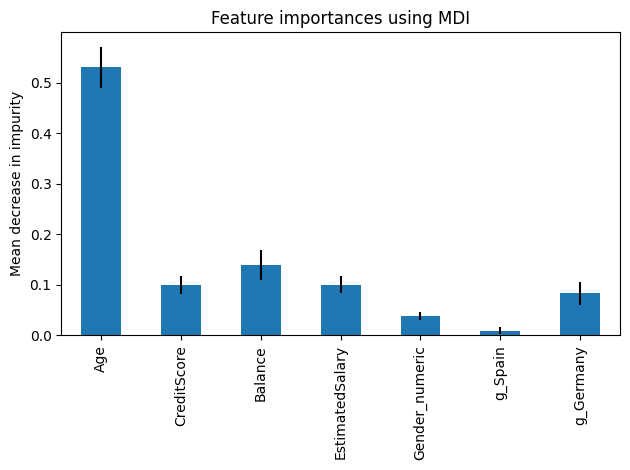

In [96]:
forest_importances = pd.Series(importances, index=features)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

## Gradient Boosting

In [97]:
from sklearn.ensemble import GradientBoostingClassifier

In [98]:
gbm = GradientBoostingClassifier(random_state = random_variable, n_estimators=100)

In [99]:
gbm.fit(x_full, data_full['Exited'])

GradientBoostingClassifier(random_state=1234)

In [100]:
predictions_gbm = gbm.predict(x_full)

In [101]:
cnf_gbm = metrics.confusion_matrix(data_full['Exited'], predictions_gbm, labels=[True, False])

## Shapley Values

In [103]:
import shap
from random import randrange


/Users/janmammen/Library/CloudStorage/OneDrive-Personal/14 OHM/00 lehre/03_ERP_Verantaltung/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [104]:
explainer = shap.TreeExplainer(gbm, model_output='probability', data=x_full[features].astype(int).values)

In [105]:
shap_values = explainer.shap_values(x_full[features])

In [106]:
shap.initjs()

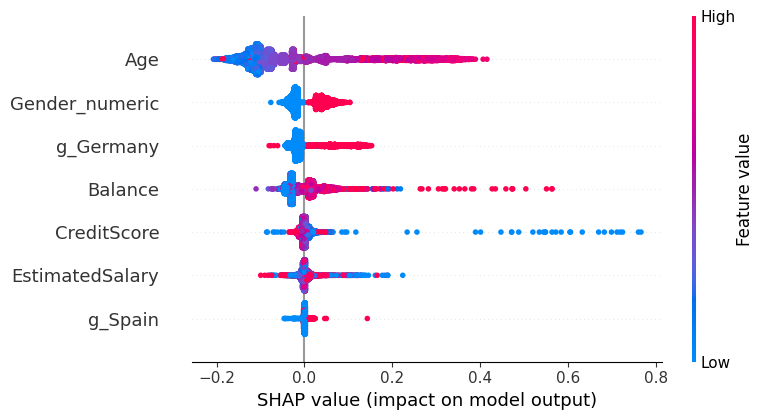

In [107]:
shap.summary_plot(shap_values, x_full[features])

In [108]:
explainer.expected_value

np.float64(0.19807413477543917)

“How much did this feature contribute to changing the model’s prediction from the average prediction?”

In [109]:
shap.force_plot(explainer.expected_value, shap_values[2], x_full.iloc[2,:][features])

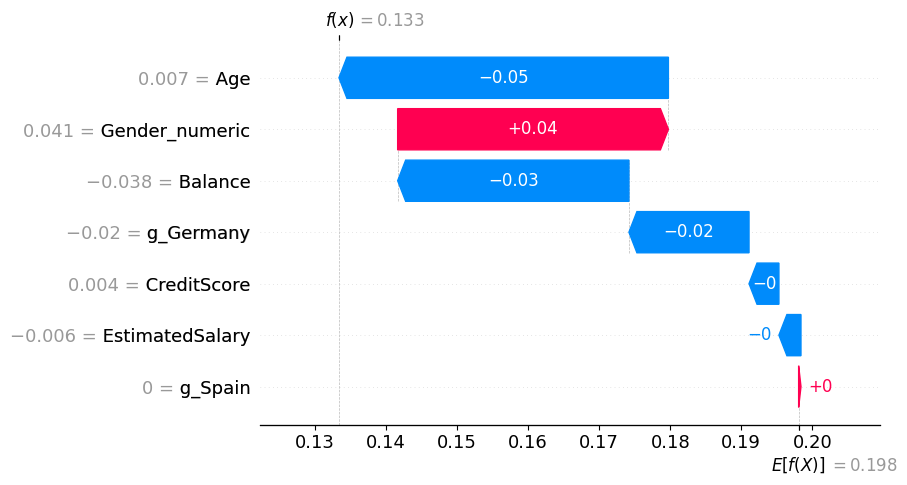

In [110]:
shap_object = shap.Explanation(
        base_values =   explainer.expected_value,
        values = shap_values[2],
        feature_names = features,
        data = shap_values[0].data)

shap.plots.waterfall(shap_object)